# Chapter 08 시각화 보강

**목표:** 질문에 맞는 차트를 선택하고, 원본 집계값을 확인한 뒤 관찰과 한계를 짧게 해석한다.

- 금액 범위: `order_status == "completed"`
- 금액 계산: `line_total = quantity × unit_price`
- 분석 단위: 차트별로 주문 상세 1행 또는 주문 1건을 명시

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
from IPython.display import display


def find_project_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / "data" / "raw").is_dir():
            return path
    raise FileNotFoundError("data/raw를 포함한 저장소 루트를 찾지 못했습니다.")


ROOT = find_project_root()
DATA_DIR = ROOT / "data" / "raw"
FIGURE_DIR = ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Linux 서버에서는 기존 공용 Noto CJK 폰트를 재사용한다.
font_candidates = [
    Path.home() / "research" / "프로그램 모음" / "tools" / "fonts" / "noto-cjk-20230817" / "NotoSansCJKkr-Regular.otf",
    Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"),
]
font_path = next((path for path in font_candidates if path.exists()), None)
if font_path:
    font_manager.fontManager.addfont(font_path)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=font_path).get_name()
else:
    warnings.warn("한글 폰트를 찾지 못했습니다. 현재 OS에 Noto Sans CJK KR 등을 설정하세요.")
plt.rcParams["axes.unicode_minus"] = False

print("저장소 루트:", ROOT.name)
print("한글 폰트:", plt.rcParams["font.family"])

저장소 루트: llm-data-analysis-study
한글 폰트: ['Noto Sans CJK KR']


## 1. 원본 데이터 확인

차트를 먼저 그리지 않고 4개 CSV의 행·열과 필요 컬럼을 확인한다.

In [2]:
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
orders = pd.read_csv(DATA_DIR / "orders.csv")
order_items = pd.read_csv(DATA_DIR / "order_items.csv")

datasets = {
    "customers": customers,
    "products": products,
    "orders": orders,
    "order_items": order_items,
}
structure = pd.DataFrame(
    [{"dataset": name, "rows": len(df), "columns": len(df.columns)} for name, df in datasets.items()]
)
display(structure)
print("order_status:", orders["order_status"].value_counts().to_dict())

,dataset,rows,columns
0,customers,150,6
1,products,100,4
2,orders,300,5
3,order_items,764,5


order_status: {'completed': 184, 'cancelled': 64, 'refunded': 52}


In [3]:
required_columns = {
    "customers": {"customer_id", "age", "gender", "city"},
    "products": {"product_id", "product_name", "category"},
    "orders": {"order_id", "customer_id", "order_date", "payment_method", "order_status"},
    "order_items": {"order_item_id", "order_id", "product_id", "quantity", "unit_price"},
}
column_checks = {
    name: required_columns[name].issubset(df.columns) for name, df in datasets.items()
}
pk_checks = {
    "customers.customer_id": customers["customer_id"].notna().all() and customers["customer_id"].is_unique,
    "products.product_id": products["product_id"].notna().all() and products["product_id"].is_unique,
    "orders.order_id": orders["order_id"].notna().all() and orders["order_id"].is_unique,
    "order_items.order_item_id": order_items["order_item_id"].notna().all() and order_items["order_item_id"].is_unique,
}
fk_invalid = {
    "orders.customer_id": int((~orders["customer_id"].isin(customers["customer_id"])).sum()),
    "order_items.order_id": int((~order_items["order_id"].isin(orders["order_id"])).sum()),
    "order_items.product_id": int((~order_items["product_id"].isin(products["product_id"])).sum()),
}
display(pd.Series(column_checks, name="required_columns_ok").to_frame())
display(pd.Series(pk_checks, name="pk_ok").to_frame())
display(pd.Series(fk_invalid, name="invalid_fk_rows").to_frame())
assert all(column_checks.values()) and all(pk_checks.values()) and not any(fk_invalid.values())

,required_columns_ok
customers,True
products,True
orders,True
order_items,True


,pk_ok
customers.customer_id,True
products.product_id,True
orders.order_id,True
order_items.order_item_id,True


,invalid_fk_rows
orders.customer_id,0
order_items.order_id,0
order_items.product_id,0


**결과 관찰:** 4개 테이블의 필수 컬럼과 기본키가 유효하고, 외래키 미매칭은 0건이다.  
**판단:** 원본을 수정하지 않고 `completed` 필터와 병합을 진행한다.

## 2. `visualization_df` 생성과 병합 검증

주문 상세에서 금액을 계산하고, `completed` 주문만 남겨 `many_to_one` 관계를 검증한다.

In [4]:
order_items = order_items.copy()
order_items["line_total"] = order_items["quantity"] * order_items["unit_price"]
completed_orders = orders.loc[orders["order_status"].eq("completed")].copy()
expected_completed_rows = int(order_items["order_id"].isin(completed_orders["order_id"]).sum())

visualization_df = (
    order_items
    .merge(
        completed_orders,
        on="order_id",
        how="inner",
        validate="many_to_one",
        indicator="orders_merge",
    )
    .merge(
        products[["product_id", "product_name", "category"]],
        on="product_id",
        how="left",
        validate="many_to_one",
        indicator="products_merge",
    )
    .merge(
        customers[["customer_id", "age", "gender", "city"]],
        on="customer_id",
        how="left",
        validate="many_to_one",
        indicator="customers_merge",
    )
)
visualization_df["order_date"] = pd.to_datetime(visualization_df["order_date"], errors="coerce")
visualization_df["order_month"] = visualization_df["order_date"].dt.to_period("M").astype(str)

merge_check = pd.Series(
    {
        "expected_completed_detail_rows": expected_completed_rows,
        "visualization_rows": len(visualization_df),
        "unmatched_products": int((visualization_df["products_merge"] != "both").sum()),
        "unmatched_customers": int((visualization_df["customers_merge"] != "both").sum()),
        "invalid_order_dates": int(visualization_df["order_date"].isna().sum()),
    },
    name="value",
)
display(merge_check.to_frame())
display(visualization_df.head())
assert len(visualization_df) == expected_completed_rows
assert merge_check[["unmatched_products", "unmatched_customers", "invalid_order_dates"]].eq(0).all()

,value
expected_completed_detail_rows,474
visualization_rows,474
unmatched_products,0
unmatched_customers,0
invalid_order_dates,0


,order_item_id,order_id,product_id,quantity,unit_price,line_total,customer_id,order_date,payment_method,order_status,orders_merge,product_name,category,products_merge,age,gender,city,customers_merge,order_month
0,1,1,100,3,102000,306000,123,2026-05-07,card,completed,both,도서 상품 100,도서,both,20,M,서울,both,2026-05
1,2,1,87,5,25000,125000,123,2026-05-07,card,completed,both,도서 상품 087,도서,both,20,M,서울,both,2026-05
2,3,1,7,3,142000,426000,123,2026-05-07,card,completed,both,도서 상품 007,도서,both,20,M,서울,both,2026-05
3,4,1,9,3,193000,579000,123,2026-05-07,card,completed,both,스포츠 상품 009,스포츠,both,20,M,서울,both,2026-05
4,13,6,83,3,24000,72000,87,2026-03-21,naver_pay,completed,both,전자기기 상품 083,전자기기,both,31,M,울산,both,2026-03


**결과 관찰:** `completed` 주문의 상세 474행이 병합 후에도 474행으로 유지되었고, 상품·고객 미매칭과 날짜 변환 실패는 0건이다.  
**판단:** 중복 증폭이나 행 손실 없이 시각화용 DataFrame이 만들어졌다.

## 3. 차트용 집계표

In [5]:
monthly_summary = (
    visualization_df.groupby("order_month", as_index=False)
    .agg(total_amount=("line_total", "sum"), order_count=("order_id", "nunique"))
    .sort_values("order_month")
)
category_summary = (
    visualization_df.groupby("category", as_index=False)
    .agg(
        total_amount=("line_total", "sum"),
        total_quantity=("quantity", "sum"),
        order_count=("order_id", "nunique"),
    )
    .sort_values("total_amount", ascending=False)
)
product_summary = (
    visualization_df.groupby(["product_id", "product_name"], as_index=False)
    .agg(
        total_amount=("line_total", "sum"),
        total_quantity=("quantity", "sum"),
        order_count=("order_id", "nunique"),
    )
    .sort_values("total_amount", ascending=False)
)
order_summary = (
    visualization_df.groupby("order_id", as_index=False)
    .agg(
        order_date=("order_date", "first"),
        payment_method=("payment_method", "first"),
        age=("age", "first"),
        city=("city", "first"),
        order_total=("line_total", "sum"),
        total_quantity=("quantity", "sum"),
    )
)
payment_summary = (
    order_summary.groupby("payment_method", as_index=False)
    .agg(order_count=("order_id", "nunique"))
    .sort_values("order_count", ascending=False)
)

display(category_summary)
display(monthly_summary)
display(product_summary.head(10))
display(order_summary.head())
display(payment_summary)

,category,total_amount,total_quantity,order_count
3,스포츠,31743000,295,85
5,전자기기,26400000,259,60
2,생활용품,23915000,272,65
1,뷰티,23383000,223,65
4,식품,16573000,133,36
0,도서,16389000,149,52
6,패션,10587000,111,33


,order_month,total_amount,order_count
0,2025-07,5869000,8
1,2025-08,15621000,18
2,2025-09,10190000,13
3,2025-10,25766000,26
4,2025-11,8812000,12
5,2025-12,11501000,14
6,2026-01,17423000,22
7,2026-02,9749000,17
8,2026-03,13429000,14
9,2026-04,17553000,23


,product_id,product_name,total_amount,total_quantity,order_count
39,41,스포츠 상품 041,5705000,35,12
11,12,식품 상품 012,4375000,25,7
8,9,스포츠 상품 009,3860000,20,6
70,72,뷰티 상품 072,3780000,20,6
69,71,전자기기 상품 071,3703000,23,5
66,68,스포츠 상품 068,3640000,26,8
78,81,전자기기 상품 081,3630000,22,6
10,11,패션 상품 011,3565000,31,7
20,22,생활용품 상품 022,3248000,29,8
86,89,생활용품 상품 089,3090000,30,11


,order_id,order_date,payment_method,age,city,order_total,total_quantity
0,1,2026-05-07,card,20,서울,1436000,14
1,6,2026-03-21,naver_pay,31,울산,1309000,15
2,9,2026-01-20,card,59,성남,236000,3
3,11,2025-11-17,card,36,울산,222000,3
4,12,2025-07-12,kakao_pay,61,인천,444000,6


,payment_method,order_count
3,naver_pay,51
2,kakao_pay,49
0,bank_transfer,45
1,card,39


In [6]:
completed_total = int(visualization_df["line_total"].sum())
total_checks = pd.Series(
    {
        "detail_total": completed_total,
        "category_total": int(category_summary["total_amount"].sum()),
        "monthly_total": int(monthly_summary["total_amount"].sum()),
        "order_total": int(order_summary["order_total"].sum()),
    },
    name="completed_amount",
)
display(total_checks.to_frame())
assert total_checks.nunique() == 1

,completed_amount
detail_total,148990000
category_total,148990000
monthly_total,148990000
order_total,148990000


**결과 관찰:** 주문 상세·카테고리·월·주문 단위 합계가 모두 148,990,000원으로 일치한다.  
**판단:** 각 차트가 같은 `completed` 금액 범위를 사용한다.

In [7]:
saved_figures = []


def save_and_show(filename):
    path = FIGURE_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    saved_figures.append(path)
    plt.show()

## 4. Bar Chart — 카테고리별 금액 비교

질문: 어느 카테고리의 `completed` 주문 금액이 가장 큰가? 범주 간 크기 비교이므로 Bar Chart를 선택한다.

,category,total_amount
3,스포츠,31743000
5,전자기기,26400000
2,생활용품,23915000
1,뷰티,23383000
4,식품,16573000
0,도서,16389000
6,패션,10587000


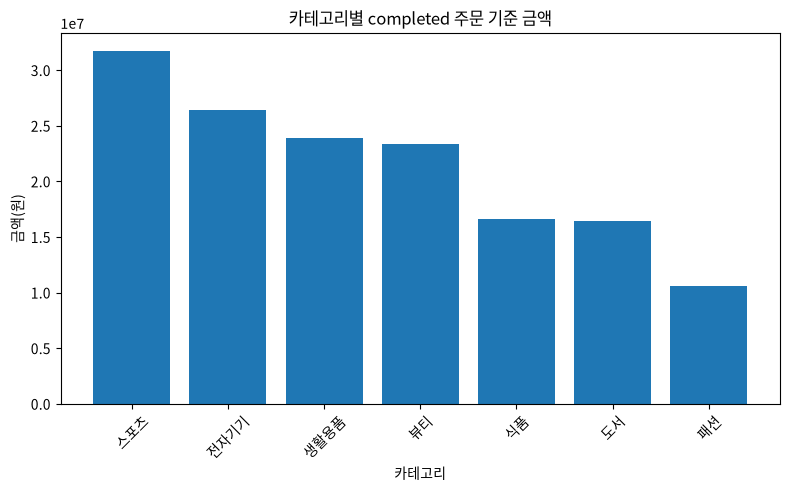

In [8]:
display(category_summary[["category", "total_amount"]])
plt.figure(figsize=(8, 5))
plt.bar(category_summary["category"], category_summary["total_amount"])
plt.title("카테고리별 completed 주문 기준 금액")
plt.xlabel("카테고리")
plt.ylabel("금액(원)")
plt.xticks(rotation=45)
save_and_show("ch08_supplement_category_amount.png")

**원본 집계값:** 스포츠 31,743,000원, 패션 10,587,000원이다.  
**결과 관찰:** 스포츠가 가장 크고 패션이 가장 작다.  
**해석·한계:** 스포츠의 완료 주문 금액이 높지만 이 차트만으로 인기, 수익성, 원인을 판단할 수는 없다.

### 추가 Bar Chart — 상품별 금액 TOP 10

,product_name,total_amount
39,스포츠 상품 041,5705000
11,식품 상품 012,4375000
8,스포츠 상품 009,3860000
70,뷰티 상품 072,3780000
69,전자기기 상품 071,3703000
66,스포츠 상품 068,3640000
78,전자기기 상품 081,3630000
10,패션 상품 011,3565000
20,생활용품 상품 022,3248000
86,생활용품 상품 089,3090000


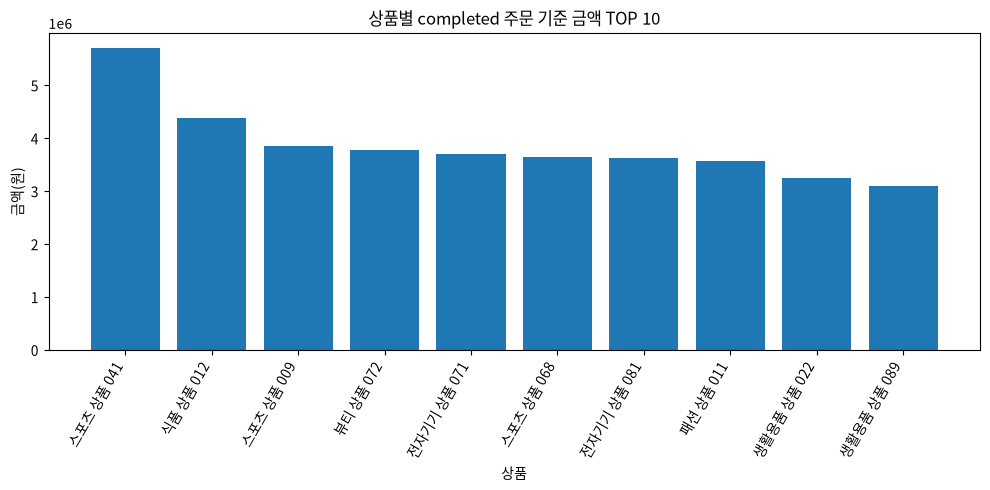

In [9]:
top10_products = product_summary.head(10)
display(top10_products[["product_name", "total_amount"]])
plt.figure(figsize=(10, 5))
plt.bar(top10_products["product_name"], top10_products["total_amount"])
plt.title("상품별 completed 주문 기준 금액 TOP 10")
plt.xlabel("상품")
plt.ylabel("금액(원)")
plt.xticks(rotation=60, ha="right")
save_and_show("ch08_supplement_top10_product_amount.png")

**결과 관찰:** `스포츠 상품 041`의 금액이 5,705,000원으로 가장 크다.  
**해석·한계:** TOP 10은 상품 간 크기 비교에 유용하지만, 전체 상품의 분포와 이익은 보여주지 않는다.

## 5. Line Chart — 월별 금액 변화

질문: `completed` 주문 금액은 월별로 어떻게 변하는가? 시간 순서가 중요하므로 Line Chart를 선택한다.

,order_month,total_amount,order_count
0,2025-07,5869000,8
1,2025-08,15621000,18
2,2025-09,10190000,13
3,2025-10,25766000,26
4,2025-11,8812000,12
5,2025-12,11501000,14
6,2026-01,17423000,22
7,2026-02,9749000,17
8,2026-03,13429000,14
9,2026-04,17553000,23


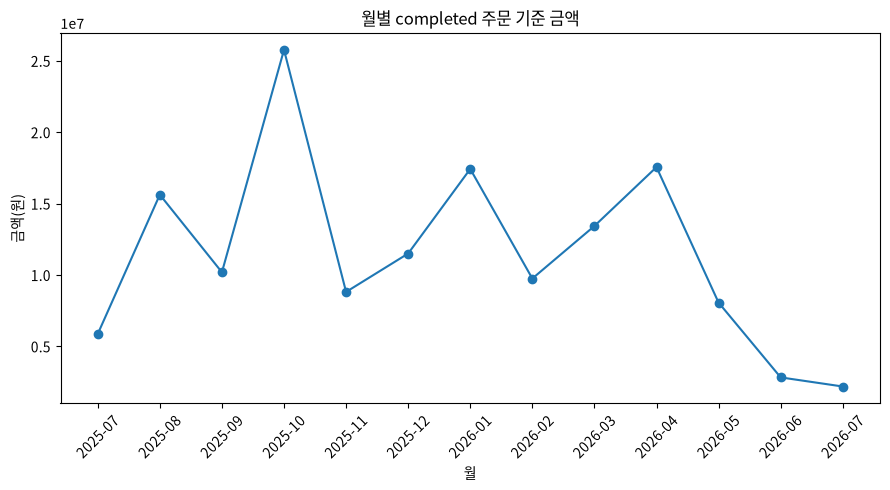

In [10]:
display(monthly_summary)
plt.figure(figsize=(9, 5))
plt.plot(monthly_summary["order_month"], monthly_summary["total_amount"], marker="o")
plt.title("월별 completed 주문 기준 금액")
plt.xlabel("월")
plt.ylabel("금액(원)")
plt.xticks(rotation=45)
save_and_show("ch08_supplement_monthly_amount.png")

**원본 집계값:** 2025-10이 25,766,000원으로 가장 크고 2026-07이 2,188,000원으로 가장 작다.  
**결과 관찰:** 일정한 증감추세보다 월별 변동이 나타난다.  
**해석·한계:** 마지막 월은 불완전한 기간일 수 있으므로 계절성이나 성장 하락을 단정하지 않는다.

## 6. Histogram — 주문금액 분포

질문: 주문 1건의 금액은 어느 구간에 모여 있는가? 숫자값의 분포를 보기 위해 Histogram을 선택한다.

,order_total
count,1.840000e+02
mean,8.097283e+05
std,4.745789e+05
min,2.000000e+04
25%,3.955000e+05
50%,7.765000e+05
75%,1.116750e+06
max,2.118000e+06


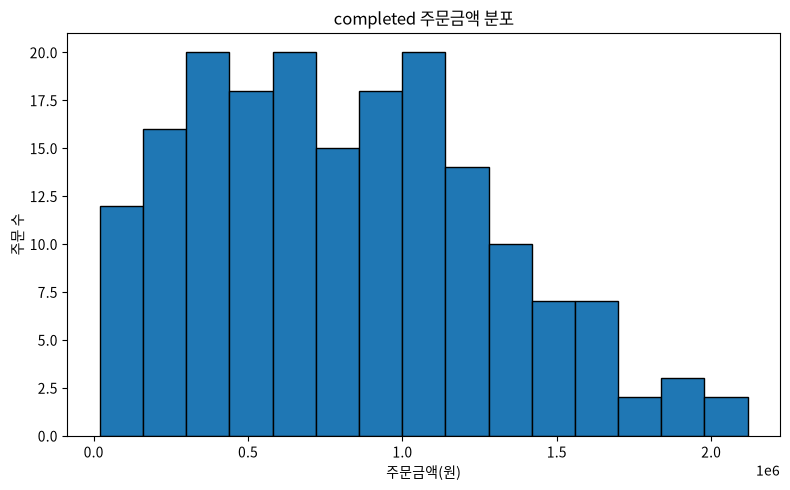

In [11]:
display(order_summary["order_total"].describe().to_frame())
plt.figure(figsize=(8, 5))
plt.hist(order_summary["order_total"], bins=15, edgecolor="black")
plt.title("completed 주문금액 분포")
plt.xlabel("주문금액(원)")
plt.ylabel("주문 수")
save_and_show("ch08_supplement_order_total_histogram.png")

**원본 집계값:** 184건의 중앙값은 776,500원, 최소·최대는 20,000원·2,118,000원이다.  
**결과 관찰:** 주문금액은 하나의 값에 집중되지 않고 넓은 구간에 분포한다.  
**해석·한계:** 큰 값은 오류가 아니라 대량 주문일 수 있으며, bin 수에 따라 보이는 모양이 달라질 수 있다.

## 7. Scatter Plot — 나이와 주문금액의 관계

질문: 고객 나이와 주문 1건 금액 사이에 선형 관계가 보이는가? 두 숫자 변수를 비교하므로 Scatter Plot을 선택한다.

피어슨 상관계수: -0.046


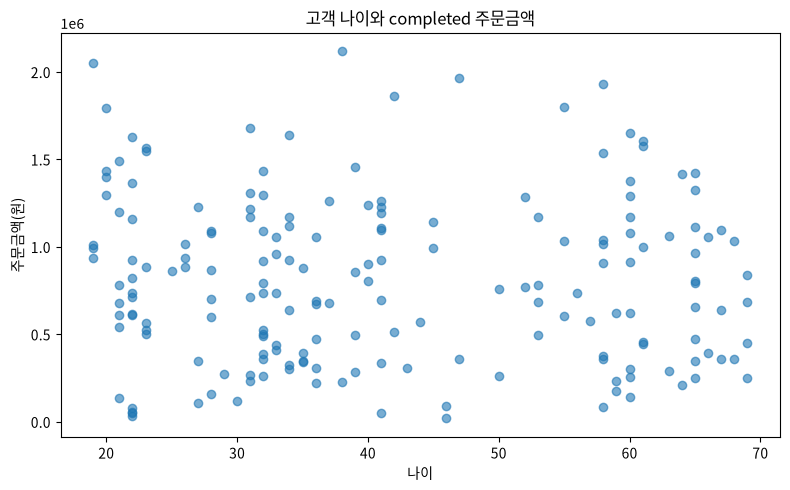

In [12]:
scatter_df = order_summary.dropna(subset=["age", "order_total"])
correlation = scatter_df["age"].corr(scatter_df["order_total"])
print(f"피어슨 상관계수: {correlation:.3f}")
plt.figure(figsize=(8, 5))
plt.scatter(scatter_df["age"], scatter_df["order_total"], alpha=0.6)
plt.title("고객 나이와 completed 주문금액")
plt.xlabel("나이")
plt.ylabel("주문금액(원)")
save_and_show("ch08_supplement_age_order_total_scatter.png")

**원본 집계값:** 나이와 주문금액의 피어슨 상관계수는 -0.046이다.  
**결과 관찰:** 점들에서 뚜렷한 선형 방향이 보이지 않는다.  
**해석·한계:** 이 표본에서 선형 관계가 거의 없으며, 상관관계는 인과관계를 증명하지 않는다.

## 8. Pie Chart — 결제수단 구성

질문: `completed` 주문의 결제수단 구성은 어떤가? 범주가 4개이고 구성비가 목적이므로 Pie Chart를 사용한다.

,payment_method,order_count
3,naver_pay,51
2,kakao_pay,49
0,bank_transfer,45
1,card,39


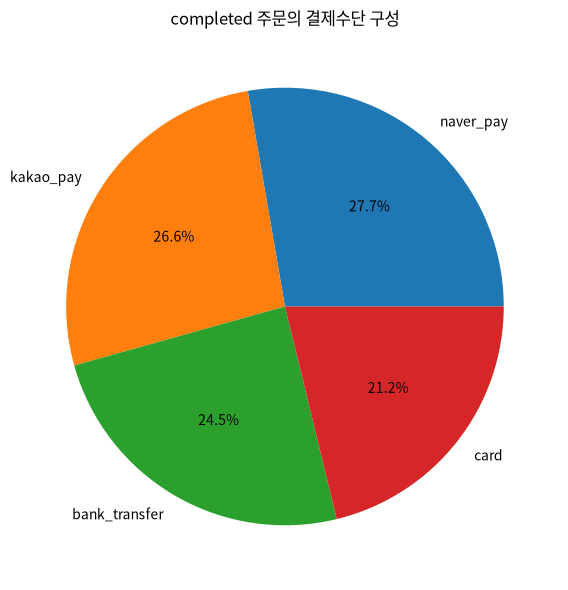

In [13]:
display(payment_summary)
plt.figure(figsize=(6, 6))
plt.pie(
    payment_summary["order_count"],
    labels=payment_summary["payment_method"],
    autopct="%1.1f%%",
)
plt.title("completed 주문의 결제수단 구성")
save_and_show("ch08_supplement_payment_share.png")

**원본 집계값:** naver_pay 51건, kakao_pay 49건, bank_transfer 45건, card 39건이다.  
**결과 관찰:** naver_pay가 가장 많지만 4개 결제수단의 격차는 크지 않다.  
**해석·한계:** 구성비만 보여주며 금액 차이나 결제수단 선택 원인은 알 수 없다.

## 9. Boxplot — 결제수단별 주문금액 분포

질문: 결제수단별 주문금액의 중앙값·분포·이상치 후보는 어떤가? 그룹별 분포를 압축해 비교하므로 Boxplot을 선택한다.

,count,median,mean,min,max
payment_method,,,,,
naver_pay,51,860000.0,852941.176471,50000,2118000
card,39,837000.0,815538.461538,20000,1800000
kakao_pay,49,804000.0,802897.959184,84000,1931000
bank_transfer,45,713000.0,763155.555556,80000,2053000


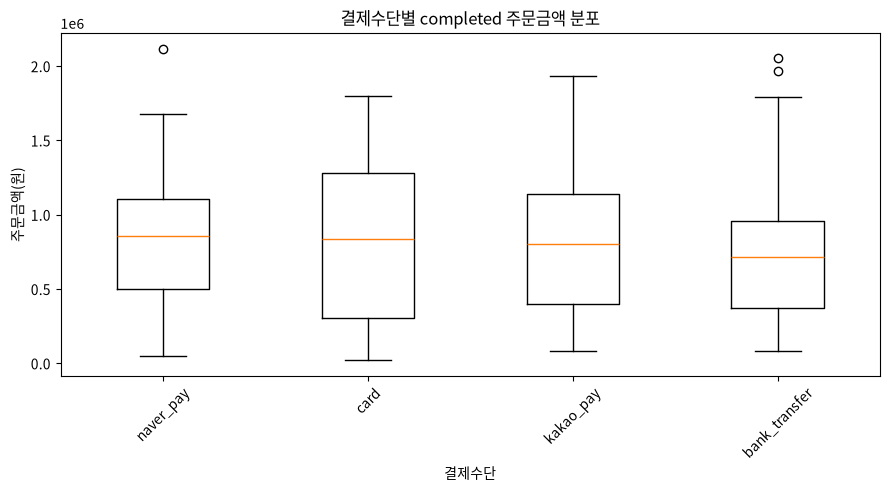

In [14]:
payment_stats = (
    order_summary.groupby("payment_method")["order_total"]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_values("median", ascending=False)
)
display(payment_stats)
payment_order = payment_stats.index.tolist()
plt.figure(figsize=(9, 5))
plt.boxplot(
    [order_summary.loc[order_summary["payment_method"].eq(method), "order_total"] for method in payment_order],
    tick_labels=payment_order,
)
plt.title("결제수단별 completed 주문금액 분포")
plt.xlabel("결제수단")
plt.ylabel("주문금액(원)")
plt.xticks(rotation=45)
save_and_show("ch08_supplement_payment_order_total_boxplot.png")

**원본 집계값:** 중앙값은 naver_pay 860,000원으로 가장 높고 bank_transfer 713,000원으로 가장 낮다.  
**결과 관찰:** 결제수단별 중앙값과 분포 폭에 차이가 보인다.  
**해석·한계:** 박스 밖의 점은 오류가 아니라 추가 확인 대상이며, 차이의 원인이 결제수단 자체라고 단정할 수 없다.

### 추가 Boxplot — 카테고리별 주문 상세 금액

이 차트의 관측 단위는 주문 1건이 아니라 **주문 상세 1행**이다.

,count,median,mean,min,max
category,,,,,
식품,42,334000.0,394595.238095,67000,930000
전자기기,78,330000.0,338461.538462,5000,825000
도서,58,250000.0,282568.965517,34000,870000
스포츠,100,241500.0,317430.000000,20000,965000
패션,37,230000.0,286135.135135,56000,870000
생활용품,83,222000.0,288132.530120,11000,940000
뷰티,76,186000.0,307671.052632,10000,1000000


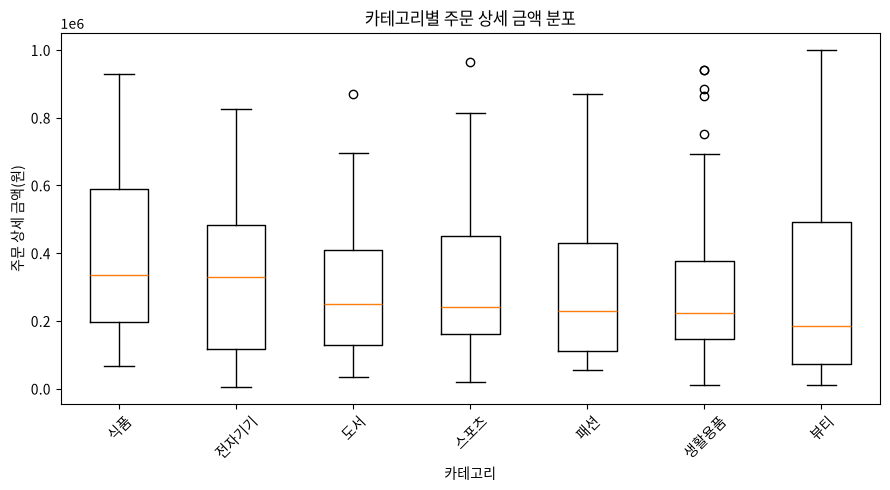

In [15]:
category_stats = (
    visualization_df.groupby("category")["line_total"]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_values("median", ascending=False)
)
display(category_stats)
category_order = category_stats.index.tolist()
plt.figure(figsize=(9, 5))
plt.boxplot(
    [visualization_df.loc[visualization_df["category"].eq(category), "line_total"] for category in category_order],
    tick_labels=category_order,
)
plt.title("카테고리별 주문 상세 금액 분포")
plt.xlabel("카테고리")
plt.ylabel("주문 상세 금액(원)")
plt.xticks(rotation=45)
save_and_show("ch08_supplement_category_line_total_boxplot.png")

**결과 관찰:** 주문 상세 중앙값은 식품 334,000원으로 가장 높고 뷰티 186,000원으로 가장 낮다.  
**해석·한계:** 주문 상세 분포와 주문 전체 분포는 다르므로 분석 단위를 혼동하지 않아야 한다.

## 10. 최종 검증

In [16]:
figure_checks = {path.name: path.exists() and path.stat().st_size > 0 for path in saved_figures}
final_checks = {
    "completed_only": visualization_df["order_status"].eq("completed").all(),
    "merge_rows_preserved": len(visualization_df) == expected_completed_rows,
    "no_product_or_customer_unmatched": (
        visualization_df["products_merge"].eq("both").all()
        and visualization_df["customers_merge"].eq("both").all()
    ),
    "totals_consistent": total_checks.nunique() == 1,
    "month_sorted": monthly_summary["order_month"].is_monotonic_increasing,
    "six_chart_types_completed": len(saved_figures) >= 6,
    "all_png_files_saved": all(figure_checks.values()),
    "privacy_safe_columns": not {"name", "email", "phone", "address"}.intersection(visualization_df.columns),
}
validation = pd.Series(final_checks, name="pass").to_frame()
display(validation)
print("저장된 PNG:")
for path in saved_figures:
    print("-", path.relative_to(ROOT))
assert validation["pass"].all()

,pass
completed_only,True
merge_rows_preserved,True
no_product_or_customer_unmatched,True
totals_consistent,True
month_sorted,True
six_chart_types_completed,True
all_png_files_saved,True
privacy_safe_columns,True


저장된 PNG:
- reports/figures/ch08_supplement_category_amount.png
- reports/figures/ch08_supplement_top10_product_amount.png
- reports/figures/ch08_supplement_monthly_amount.png
- reports/figures/ch08_supplement_order_total_histogram.png
- reports/figures/ch08_supplement_age_order_total_scatter.png
- reports/figures/ch08_supplement_payment_share.png
- reports/figures/ch08_supplement_payment_order_total_boxplot.png
- reports/figures/ch08_supplement_category_line_total_boxplot.png


## 최종 판단

- 질문 → 원본 표 확인 → 집계 → 차트 선택 → 검증 → 해석 순서를 유지했다.
- Bar·Line·Histogram·Scatter·Pie·Boxplot의 용도와 분석 단위를 구분했다.
- 그래프는 패턴을 보여주지만 원인을 증명하지 않으며, 이상치 후보를 오류로 단정하지 않았다.